# Names: Aeden Rask, Diego McGrath, Imaan Shakoor

# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## 1. The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


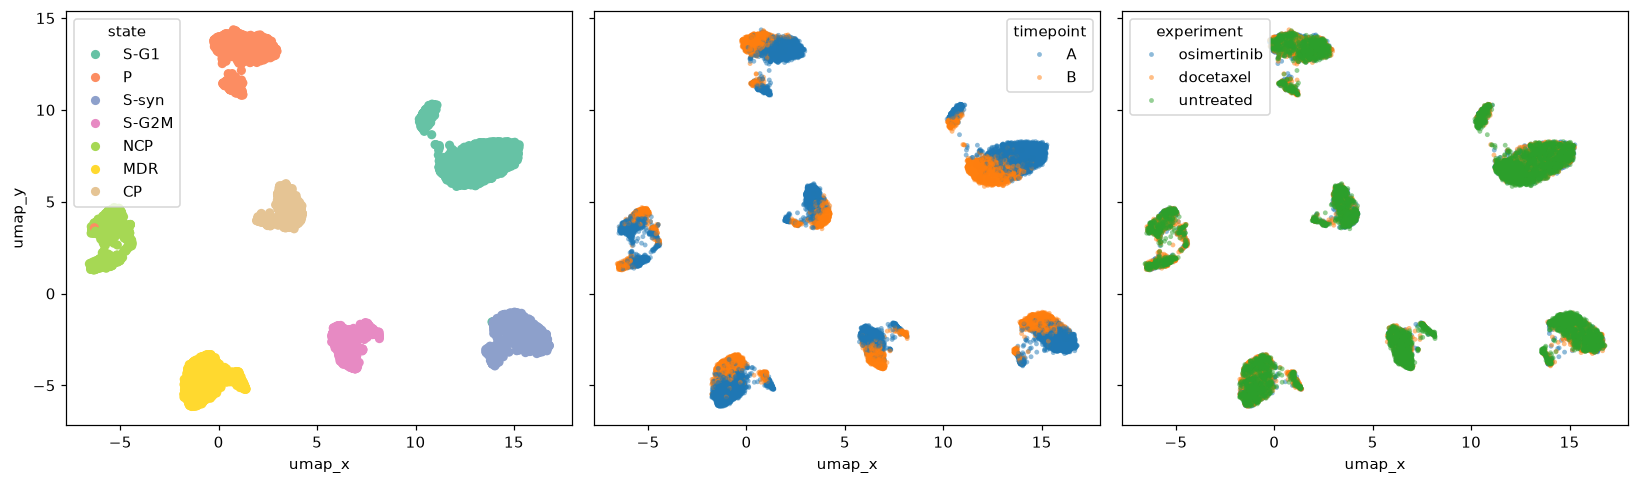

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."

In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

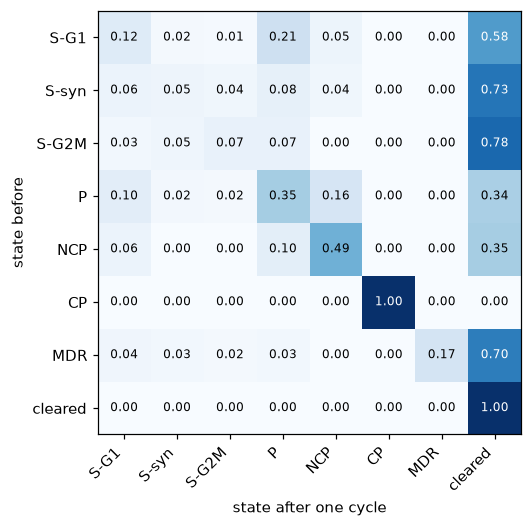

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

CP is absorbing under osimertinib because when looking at the matrix, we see that a cell that starts in CP has an estimated 100% chance of still being CP after one cycle of osimertinib. It suggests that osimertinib alone is not good enough to treat the tumor, as it does not kill them nor push them into another state.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

After one cycle, osimertinib cannot fully eliminate any of them, but considering the high probability for starting states like S-syn, S-G2M, and MDR to be cleared after just one cycle, it may be possible that after multiple rounds, they could be completely eliminated. They will likely clear fastest because of this. Over many cycles, it should eventually eliminate S-G1, S-syn, S-G2M, P, NCP and MDR though since every one of the rows sends some probability to cleared each cycle and none of them can move to CP. Osimertinib can't ever eliminate CP because Cp -> CP = 1.00.

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

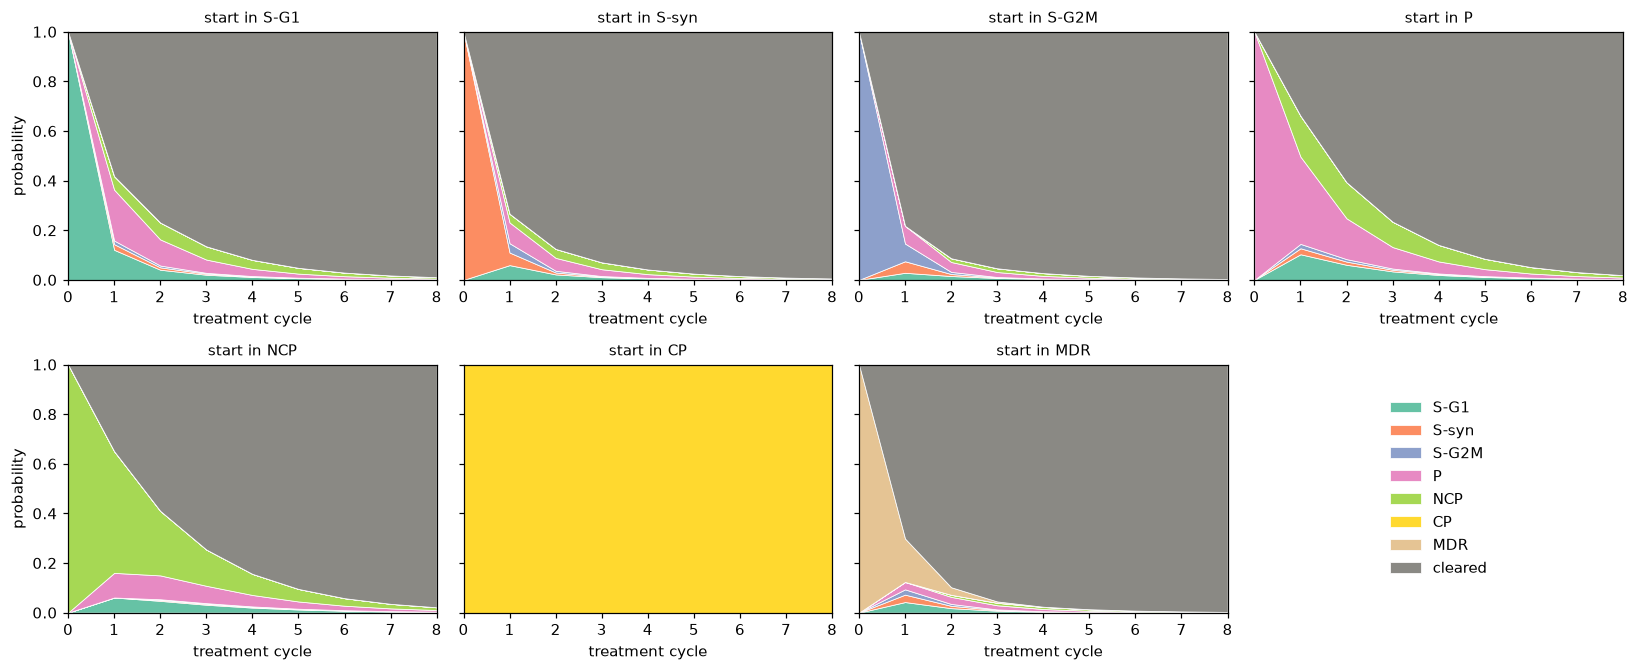

fraction alive after 3 cycles, starting in S-G1 : 0.135
fraction alive after 3 cycles, starting in S-syn : 0.071
fraction alive after 3 cycles, starting in S-G2M : 0.047
fraction alive after 3 cycles, starting in P : 0.234
fraction alive after 3 cycles, starting in NCP : 0.254
fraction alive after 3 cycles, starting in CP : 1.0
fraction alive after 3 cycles, starting in MDR : 0.045
fraction alive after 3 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 3)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 3 cycles, starting in", s, ":", round(v, 3))

In [16]:
  alive8 = {s: 1 - evolve(basis(s, P_hat), P_hat, 8)[-1, -1] for s in OUTCOMES}
  for s, v in alive8.items():
      print("frac alive after 8 cycles, starting in", s, ":", round(v, 3))

frac alive after 8 cycles, starting in S-G1 : 0.011
frac alive after 8 cycles, starting in S-syn : 0.006
frac alive after 8 cycles, starting in S-G2M : 0.004
frac alive after 8 cycles, starting in P : 0.019
frac alive after 8 cycles, starting in NCP : 0.022
frac alive after 8 cycles, starting in CP : 1.0
frac alive after 8 cycles, starting in MDR : 0.003
frac alive after 8 cycles, starting in cleared : 0.0


<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



After 8 cycles, every state aside from CP is near 0, but not completely 0, meaning that they are not entirely clear. However, they are approaching 0 with every cycle, ending cycle 8 with about 0.3-2% still alive across the different starting states. Osmertinib eliminates S-G1, S-syn, S-G2M, P, NCP, and MDR in the long run. CP is the one starting cell that does not decrease with each new cycle and remains 100% alive. 

NCP, followed by P, where after 8 cycles, 2.2% and 1.9% were still alive. This suggests that they last around the longest out of the states that can be cleared.

CP sticks around for the most cycles of drugs as it appears it is not affected by the drug. Among the states that can be cleared, NCP sticks around the longest.

CP has the highest proportion of alive cells after 3 cycles, with 100% still alive. Among the clearable states, NCP has the most alive after 3 cycles (25.4%), then P (23.4%).

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

pi_mix: {'S-G1': np.float64(0.247), 'S-syn': np.float64(0.148), 'S-G2M': np.float64(0.099), 'P': np.float64(0.153), 'NCP': np.float64(0.102), 'CP': np.float64(0.097), 'MDR': np.float64(0.153), 'cleared': np.float64(0.0)}


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


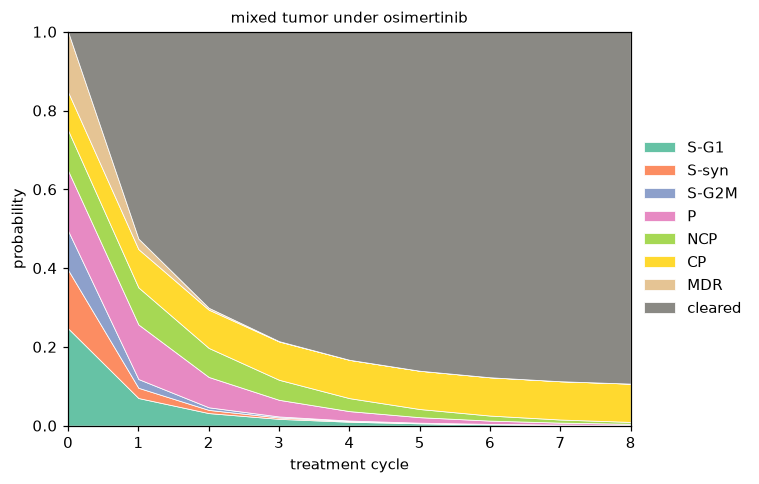

In [17]:
# Your code here

pi_mix = (cells[cells["timepoint"] == "A"]["state"]
          .value_counts(normalize=True)
          .reindex(OUTCOMES, fill_value=0)
          .to_numpy())   # TODO: set this equal to the starting vector from timepoint A

print("pi_mix:", dict(zip(OUTCOMES, pi_mix.round(3))))

# evolve pi_mix and plot the results

traj_mix = evolve(pi_mix, P_hat, N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_trajectory(traj_mix, ax, "mixed tumor under osimertinib")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP by far dominates the remaining cluster. After 8 cycles, 10.7% of the tumor is alive, where 9.7% of that is CP, meaning CP is about 90% of the surviving cells. This is because osimertinib does not affect CP starting states, so these cells will never be cleared with just using this one drug. The long-run endpoint is a stationary distribution, and it is determined by the absorbing states in the transition matrix. With just osimertinib, every state except CP "loses" some of their probability to the cleared state, while CP keeps the same transition probability of 1 forever with no other state transitioning into it, so 9.7% of the tumor will always live on as CP while the rest could eventually clear.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [18]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position

def transition_matrix(experiment):
    sub = cells[cells["experiment"] == experiment]
    at_A = sub[sub.timepoint == "A"][["lineage_tag", "state"]]
    at_B = sub[sub.timepoint == "B"][["lineage_tag", "state"]]

    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["state_B"] = pairs["state_B"].fillna("cleared")

    counts = (pd.crosstab(pairs.state_A, pairs.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = counts.div(counts.sum(axis=1), axis=0)
    assert P.notna().all().all(), f"a state has no cells at A in {experiment}"

    P.loc["cleared"] = pd.Series({c: (1 if c == "cleared" else 0) for c in P.columns})
    return P

P_doc_df = transition_matrix("docetaxel")
P_holiday_df = transition_matrix("untreated")

P_osi = P_hat.to_numpy()
P_doc = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()

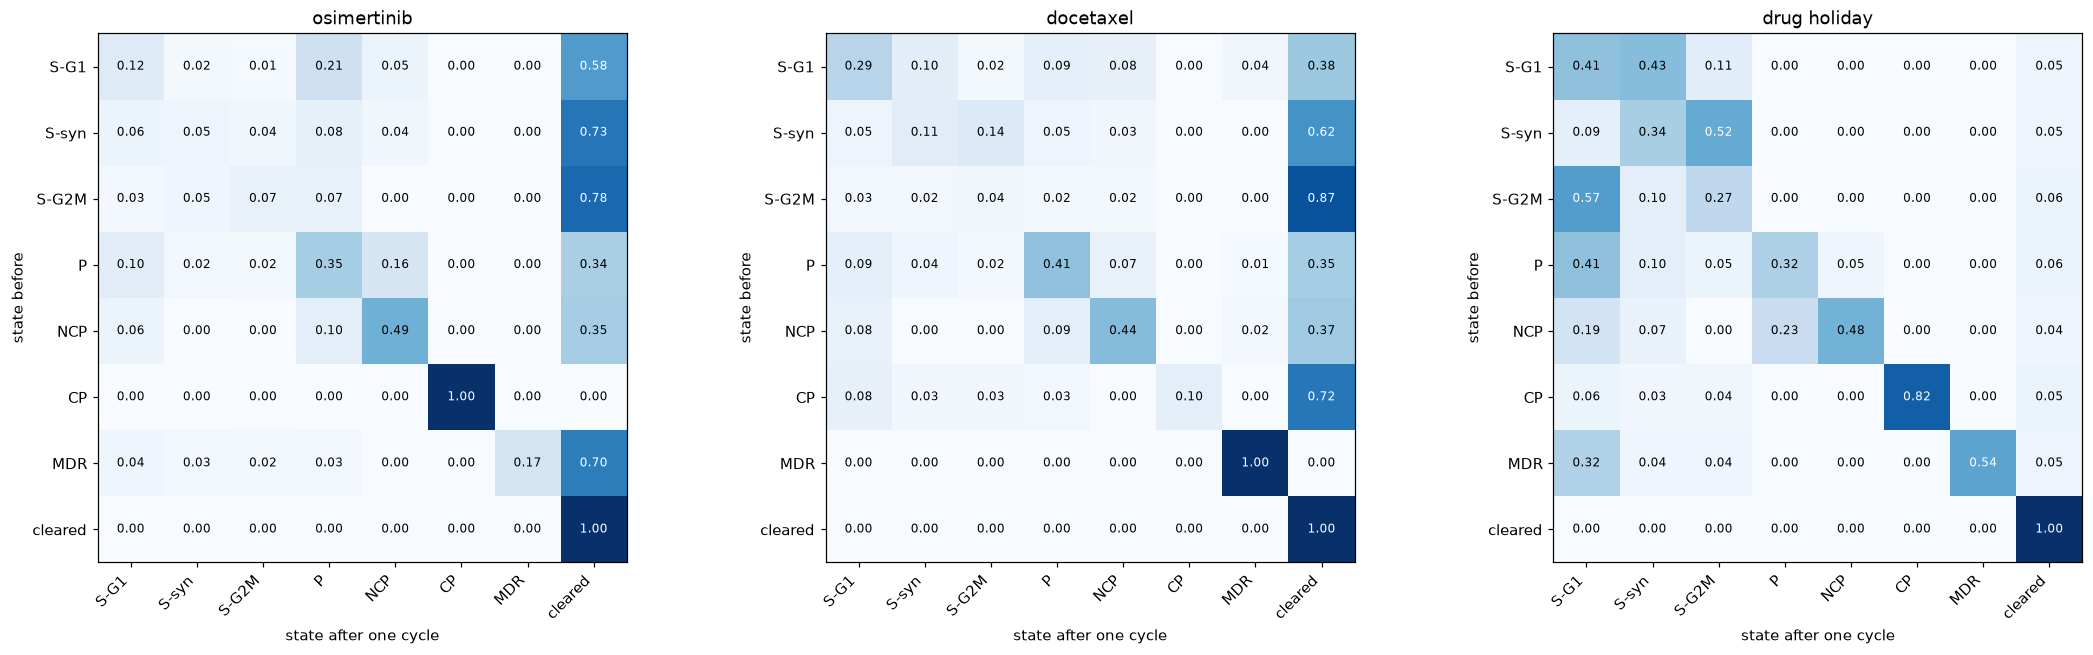

In [19]:
#Plot the transition matrices for docetaxel and the drug holiday.

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
show_matrix(P_hat, "osimertinib", ax=axes[0])
show_matrix(P_doc_df, "docetaxel", ax=axes[1])
show_matrix(P_holiday_df, "drug holiday", ax=axes[2])
plt.tight_layout()
plt.show()

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


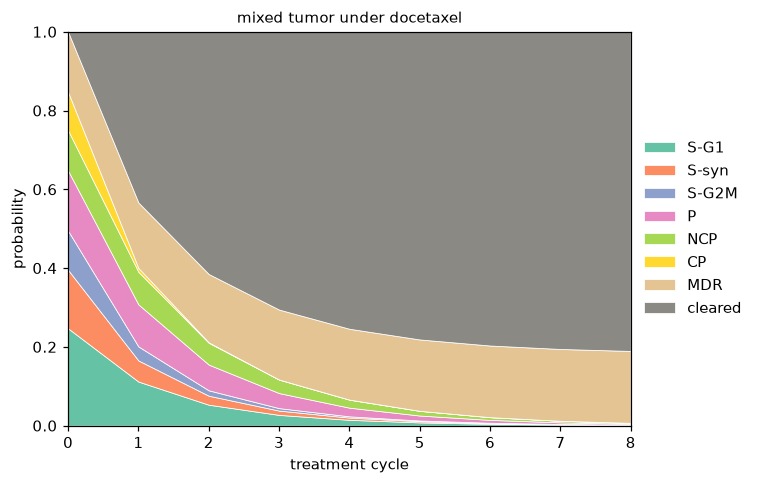

In [20]:
# Simulate the evolution of pi_mix under docetaxel 

traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_trajectory(traj_doc, ax, "mixed tumor under docetaxel")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
- Docetaxel kills some sensitive states but dividing cells the hardest (S-syn -> 0.62, S-G2M -> 0.87), and it also clears most of the CP cells that osimertinib left untouched (CP -> CP drops from 1.00 to 0.10). The new feature is that MDR has a self-loop of 1.00 under docetaxel, making it absorbing, while under osimertinib MDR mostly dies. Docetaxel also creates MDR as S-G1 -> MDR = 0.04 & P -> MDR = 0.01 & NCP ->MDR = 0.02. Under the drug holiday, cells keep moving among the sensitive states and CP has the highest self-loop (0.82), but no non-cleared state is absorbing. Cleared is absorbing in all three matrices by construction, and the holiday matrix has a small (~5%) clearing rate in every row. Osimertinib has CP as absorbing, docetaxel has MDR as absorbing, and the holiday has none.

2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?
- Under 8 cycles of docetaxel, CP is eliminated within about three cycles, but the tumor is not cured. About 81% of the tumor ends up cleared, and the remaining ~18% is MDR, which is absorbing and therefore permanent (MDR grows from 15.3% -> 18.3% over the 8 cycles; shows docetaxel turning other cells to MDR). Osimertinib left ~10% of the tumor as CP after 8 cycles, so each drug alone leaves behind the population it cannot kill.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [21]:
P_alt = P_osi @ P_doc 
P_alt_doc = P_doc @ P_osi
N_PAIRS = N_CYCLES // 2 

traj_alt = evolve(pi_mix, P_alt, N_PAIRS)        # 4 pairs, osimertinib first
traj_alt_doc = evolve(pi_mix, P_alt_doc, N_PAIRS)    # 4 pairs, docetaxel first

comparison = pd.DataFrame({"4 pairs alternating (osi first)": traj_alt[-1],
                           "4 pairs alternating (doc first)": traj_alt_doc[-1]}, 
                          index=OUTCOMES).round(4)
display(comparison)

print("fraction alive after 8 rounds:")
for name in comparison.columns:
    print(f"  {name}: {1 - comparison.loc['cleared', name]:.4f}")

,4 pairs alternating (osi first),4 pairs alternating (doc first)
S-G1,0.0016,0.0014
S-syn,0.0005,0.0003
S-G2M,0.0003,0.0002
P,0.0030,0.0031
NCP,0.0033,0.0038
CP,0.0000,0.0000
MDR,0.0007,0.0003
cleared,0.9906,0.9908


fraction alive after 8 rounds:
  4 pairs alternating (osi first): 0.0094
  4 pairs alternating (doc first): 0.0092


1. After 8 rounds, osmertinib alone leaves 10.7% of the mixed tumor alive (mostly Cp, 9.7%), and docetaxel alone leaves 19% (mostly MDR, 18.3%). Alternating leaves either 0.94% (osmertinib 1st) or 0.92% (docetaxel 1st). That's ~11x fewer survivng cells than osmertinib alone and ~20x fewer than docetaxel alone because each drug kills the population the other one cant.

2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
- The order makes almost no difference for this tumor. Starting with osimertinib leaves 0.94% alive after 8 rounds, and starting with docetaxel leaves 0.92%, a gap of 0.02%. Both drugs clear most of the tumor, and whichever drug goes second cleans up what the first one left.

In [22]:
P_hol_osi = P_holiday @ P_osi   # holiday first, then osimertinib (pair product)
P_osi_hol = P_osi @ P_holiday   # osimertinib first, then holiday (pair product)
P_doc_hol = P_doc @ P_holiday   # docetaxel first, then holiday (pair product)

traj_holiday  = evolve(pi_mix, P_holiday, N_CYCLES)                    # 8 cycles of holiday
traj_osi_hol  = evolve(pi_mix, P_osi_hol, N_PAIRS)                     # 4 pairs, osi then holiday
traj_doc_hol  = evolve(pi_mix, P_doc_hol, N_PAIRS)                     # 4 pairs, doc then holiday
traj_alt_ref  = evolve(pi_mix, P_osi @ P_doc, N_PAIRS)                 # reference: 4 pairs osi/doc

comparison = pd.DataFrame({"8 cycles holiday": traj_holiday[-1],
                           "4 pairs osi then holiday": traj_osi_hol[-1],
                           "4 pairs doc then holiday": traj_doc_hol[-1],
                           "4 pairs osi then doc (reference)": traj_alt_ref[-1]},
                          index=OUTCOMES).round(4)
display(comparison)

print("fraction alive after 8 cycles:")
for name in comparison.columns:
    print(f"  {name}: {1 - comparison.loc['cleared', name]:.4f}")

,8 cycles holiday,4 pairs osi then holiday,4 pairs doc then holiday,4 pairs osi then doc (reference)
S-G1,0.2385,0.0149,0.0321,0.0016
S-syn,0.2005,0.0077,0.0169,0.0005
S-G2M,0.1897,0.0050,0.0115,0.0003
P,0.0007,0.0068,0.0073,0.0030
NCP,0.0007,0.0055,0.0065,0.0033
CP,0.0199,0.0440,0.0000,0.0000
MDR,0.0012,0.0001,0.0184,0.0007
cleared,0.3488,0.9160,0.9072,0.9906


fraction alive after 8 cycles:
  8 cycles holiday: 0.6512
  4 pairs osi then holiday: 0.0840
  4 pairs doc then holiday: 0.0928
  4 pairs osi then doc (reference): 0.0094


3.  In what situation would a drug holiday help clear the tumor?

- A holiday helps when the tumor is only getting one drug. Osmertinib then holiday (x4) leaves 8.4% alive compared with 10.7% for 8 cycles of osmertinib alone. Docetaxel then holiday (x4) leaves 9.3% compared with 19% for docetaxel alone. Without a drug, resistant cells can drift back to sensitive states so that the next drug cycle can kill them. A holiday alone barely works (only ~35% cleared after 8 cycles) and never beats alternating the two drugs. 

In [23]:
def run_schedule(pi0, schedule):
    traj = [np.asarray(pi0, dtype=float)]
    for P in schedule:
        traj.append(traj[-1] @ P)
    return np.array(traj)

def rounds_to_clear(pi0, schedule, threshold=0.01):
    """Number of single cycles until fraction alive < threshold, or None within the schedule."""
    alive = 1 - run_schedule(pi0, schedule)[:, -1]
    hits = np.where(alive < threshold)[0]
    return int(hits[0]) if len(hits) else None

LONG = 20
plans = {
    "osi": [P_osi] * LONG,
    "doc": [P_doc] * LONG,
    "alt osi->doc": [P_osi, P_doc] * (LONG // 2),
    "alt doc->osi": [P_doc, P_osi] * (LONG // 2),
}

start_vectors = {s: basis(s, P_hat) for s in STATES}
start_vectors["mixed"] = pi_mix

rx = pd.DataFrame({plan: {name: rounds_to_clear(pi0, sched)
                          for name, pi0 in start_vectors.items()}
                   for plan, sched in plans.items()})
display(rx)

# Best plan per starting state: fewest rounds, ignoring plans that never clear
rx_filled = rx.fillna(np.inf)
prescription = pd.DataFrame({
    "best plan": rx_filled.idxmin(axis=1),
    "rounds": rx_filled.min(axis=1).replace(np.inf, np.nan),
})
display(prescription)

,osi,doc,alt osi->doc,alt doc->osi
S-G1,9.0,NaN,8,9
S-syn,7.0,10.0,7,7
S-G2M,6.0,6.0,6,6
P,10.0,NaN,9,9
NCP,10.0,NaN,10,10
CP,NaN,9.0,8,7
MDR,6.0,NaN,7,8
mixed,NaN,NaN,8,8


,best plan,rounds
S-G1,alt osi->doc,8.0
S-syn,osi,7.0
S-G2M,osi,6.0
P,alt osi->doc,9.0
NCP,osi,10.0
CP,alt doc->osi,7.0
MDR,osi,6.0
mixed,alt osi->doc,8.0


4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.
- Osimertinib alone is the best choice for S-syn, S-G2M, NCP, and MDR, since adding docetaxel doesn’t speed clearance. S-G1 and P benefit from alternating with osimertinib first, which is 1 round faster. CP needs docetaxel first (7 rounds vs. 9 for docetaxel alone), since osimertinib never clears it. For the mixed tumor, alternating with osimertinib first clears it in 8 rounds, the same as docetaxel first. These counts assume a 1% threshold and ignore toxicity, which the model doesn’t include.

## 6. Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [24]:
rng = np.random.default_rng(100)

In [25]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [26]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

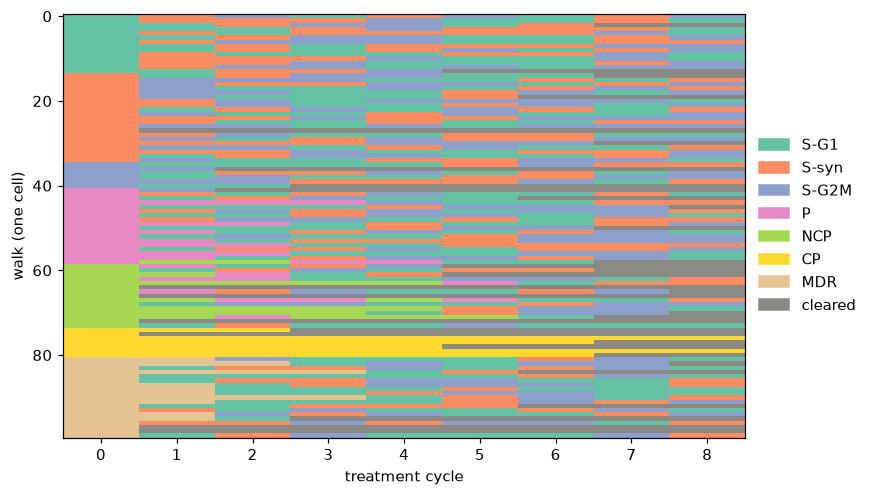

In [27]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [28]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

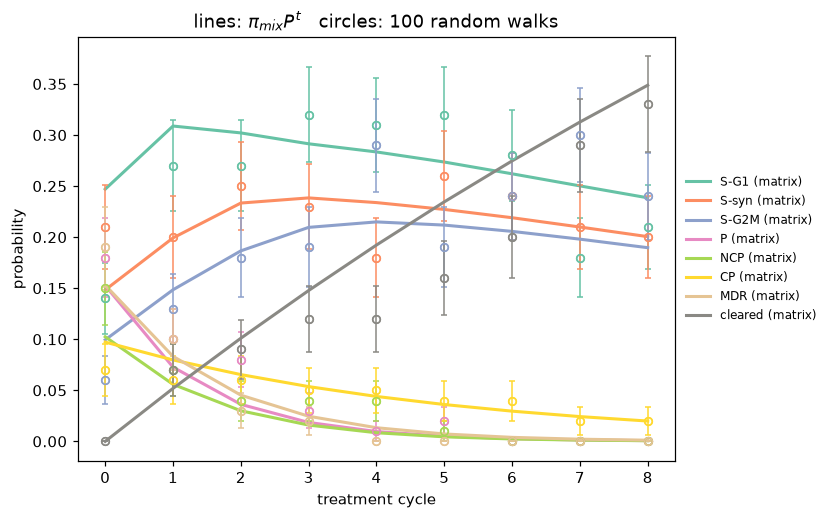

In [29]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

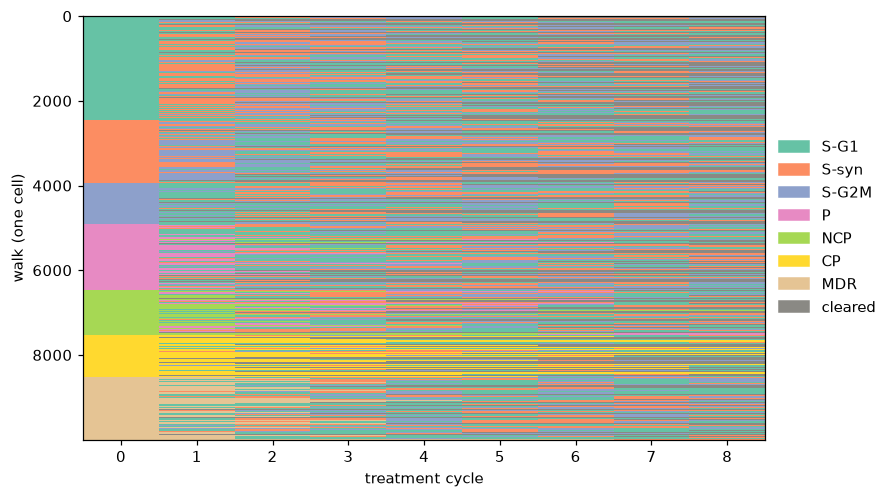

In [30]:
rng_10k = np.random.default_rng(100)   # fixed seed: same "random" numbers every run

N_WALKS = 10000
starts = rng_10k.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng_10k) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [31]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

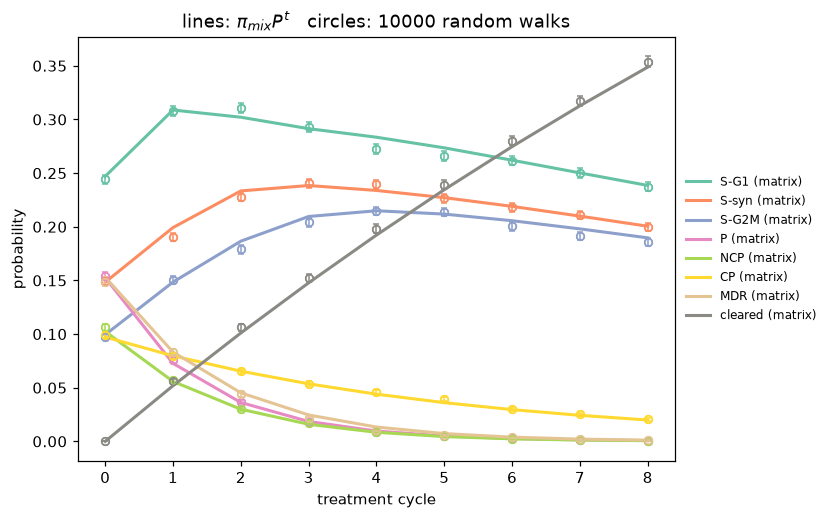

In [32]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

 How does the gap between the circles and the lines change? Why?

- With 100 walks, the circles scatter all around the lines. The error bars look like they reach ~+/-0.05. With 10,000 walks, the circles sit almost on top of the lines, and the error bars shrink to what looks like ~+/-0.005. This is because the lines are the exact matrix calculation pi_mix * P^t. There's no randomness in it, so it doesn't depend on N_WALKS. Each circle is a sample proportion - the fraction of the simulated cells that land in a given state at a given cycle. The LLN states that a sample proportion gets closer to the true probability as n increases. Its standard error is SD/sqrroot(N) -> we used 100x more walks, so sqrroot(100) = 10, so the error bars and gaps should shrink by aboout 10x. Tumor-wise, this means that a small tumor (100 cells) can differ noticeably from the expected proportions just by chance, whereas a large tumor (10k cells) behaves almost exactly like the transition matrix predicts. I also noticed the error bars are the smallest for rare states (in both cases) like P, NCP, and CP because a proportion that's already near 0 has little spread.

## 7. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [33]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

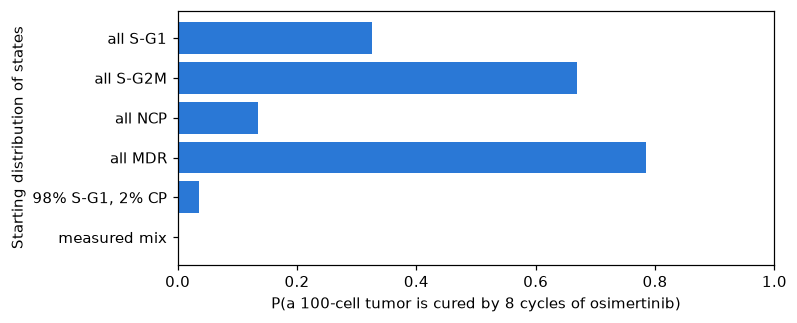

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.325,1.110,0.000
all S-G2M,0.670,0.380,0.000
all NCP,0.135,2.125,0.000
all MDR,0.785,0.235,0.000
"98% S-G1, 2% CP",0.035,3.130,0.625
measured mix,0.000,10.790,0.906


In [34]:
rng_tumor = np.random.default_rng(100)

N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng_tumor) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

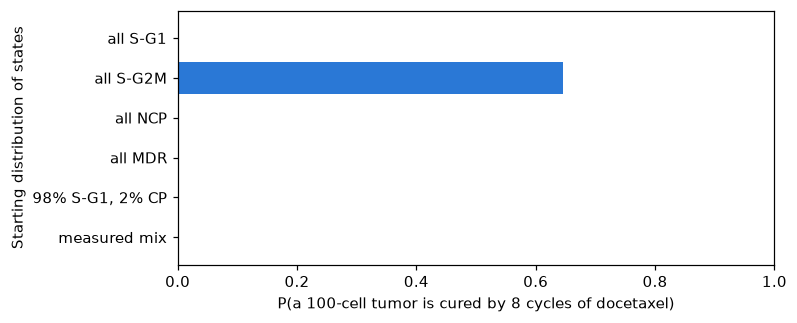

,P(cured),mean surviving cells,share of survivors that are CP,share of survivors that are MDR
start,,,,
all S-G1,0.000,6.870,0.0,0.843
all S-G2M,0.645,0.500,0.0,0.710
all NCP,0.000,6.655,0.0,0.778
all MDR,0.000,100.000,0.0,1.000
"98% S-G1, 2% CP",0.000,6.830,0.0,0.865
measured mix,0.000,18.710,0.0,0.965


In [35]:
rng_tumor = np.random.default_rng(100)

N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng_tumor) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1),
                 "share of survivors that are MDR":
                     (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1)})
results_doc = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results_doc.index[::-1], results_doc["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results_doc.round(3)

In [36]:
display(P_doc_df.round(3))

state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.293,0.102,0.020,0.091,0.082,0.0,0.035,0.376
S-syn,0.050,0.111,0.136,0.050,0.032,0.0,0.000,0.620
S-G2M,0.028,0.025,0.035,0.021,0.021,0.0,0.000,0.870
P,0.090,0.040,0.021,0.409,0.073,0.0,0.015,0.352
NCP,0.075,0.000,0.003,0.094,0.436,0.0,0.022,0.370
CP,0.079,0.034,0.034,0.028,0.000,0.1,0.000,0.724
MDR,0.000,0.000,0.000,0.000,0.000,0.0,1.000,0.000
cleared,0.000,0.000,0.000,0.000,0.000,0.0,0.000,1.000


What do the results look like?

- The results show that under 8 cycles of docetaxel, almost no type of tumor is cured. The only one that is cured and has a bar in the bar chart is an all-S-G2M tumor, which is cured 64.5% of the time, which is similar to osimertinib's tumor cure probability of 67%. Every other starting tumor has P(cured)=0. An all-MDR tumor keeps all 100 cells because MDR is absorbing under docetaxel (MDR -> MDR = 1.00 above). Tumors that start as all S-G1 or all NCP are also not cured, even though docetaxel kills ~37% of those cells each cycle (heatmap). Each cycle, docetaxel pushes a small fraction of S-G1 (3.5%), P (1.5%), and NCP (2.2%) cells into MDR. Over 8 cycles and 100 cells, at least one cell almost always makes the switch to MDR, and then once it does it can never be cleared by docetaxel. That's why we see that 71-96.5% of the surviving cells are MDR. Docetaxel does eliminate CP, we can see that no survivors are CP in any scenario, including the part S-G1 & part CP tumor, which osmertinib was only able to cure 3.5% of the time. The measured mix ends with ~19 surviving cells (96.5% MDR) compared with ~11 (91% CP) under osmertinib. So, each drug alone leaves behind a different resistant population (osmertinib ->CP, docetaxel->MDR), which is why neither drug can cure the mixed tumor by themselves and why alternating the drugs works better (seen in Part 5).

## 8. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [37]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

In [38]:
# write a function that runs 1000 random walks and saves them
def simulate_walks(pi0, P, n_cells, n_cycles, rng):
    '''Run one random walk per cell and return all of the paths (a list of lists).'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    walks = []
    for s0 in starts:
        walks.append(random_walk(int(s0), P, n_cycles, rng))
    return walks


#persister stay for 3+ consec. cycles?
def stayed_persister(path, min_cycles=3):
    '''True if the path is in P or NCP for min_cycles or more drug cycles in a row (not counting the start).'''
    run = 0
    longest = 0
    for i in path [1:]:
        if OUTCOMES[i] == "P" or OUTCOMES[i] == "NCP":
            run = run + 1
        else:
            run = 0
        if run > longest:
            longest = run
    if longest >= min_cycles:
        return True
    else:
        return False


#cells stayed in persister state consec. out of total
def fraction_persistent(walks):
    '''Fraction of cells in one tumor that became permanently resistant.'''
    count = 0
    for path in walks:
        if stayed_persister(path):
            count = count + 1
    return count / len(walks)

In [39]:
P_i = OUTCOMES.index("P")
NCP_i = OUTCOMES.index("NCP")
G1_i = OUTCOMES.index("S-G1")
C_i = OUTCOMES.index("cleared")

print(stayed_persister([G1_i, P_i, NCP_i, P_i, C_i]))
print(stayed_persister([P_i, P_i, G1_i, P_i, P_i]))
print(stayed_persister([P_i, NCP_i, C_i, C_i]))

True
False
False


In [40]:
rng_pr = np.random.default_rng(100)

N_PR_CELLS, N_PR_TUMORS, N_PR_CYCLES = 1000, 100, 8

#repeat for all tumors one PR fraction/tumor
fractions_osi = []
for _ in range(N_PR_TUMORS):
    walks = simulate_walks(pi_mix, P_osi, N_PR_CELLS, N_PR_CYCLES, rng_pr)
    fractions_osi.append(fraction_persistent(walks))
fractions_osi = np.array(fractions_osi)

#report mean +/- SEM for osimertinib
mean_osi = np.mean(fractions_osi)
sem_osi = np.std(fractions_osi) / np.sqrt(len(fractions_osi))
print(f"osimertinib, {N_PR_CYCLES} cycles: mean PR fraction = {mean_osi:.4f} +/- {sem_osi:.4f} (SEM)")

#compare to 10% threshold using  95% CI
low = mean_osi - 1.96 * sem_osi
high = mean_osi + 1.96 * sem_osi
print(f"95% CI: ({low:.4f}, {high:.4f})")
print("fraction of tumors with more than 10% PR cells:", np.mean(fractions_osi > 0.10))

osimertinib, 8 cycles: mean PR fraction = 0.0821 +/- 0.0009 (SEM)
95% CI: (0.0804, 0.0837)
fraction of tumors with more than 10% PR cells: 0.01


In [41]:
#which matrix go w/ each drug name
DRUG_MATRICES = {"osimertinib": P_osi, "docetaxel": P_doc, "holiday": P_holiday}


def make_schedule(treatment, n_cycles):
    '''Return a list of drug names, one per cycle.'''
    schedule = []
    for c in range(n_cycles):
        if treatment == "osimertinib alone":
            schedule.append("osimertinib")
        elif treatment == "docetaxel alone":
            schedule.append("docetaxel")
        elif treatment == "alternating OD":
            if c % 2 == 0:
                schedule.append("osimertinib")
            else:
                schedule.append("docetaxel")
        elif treatment == "docetaxel with holiday":
            if c % 2 == 0:
                schedule.append("docetaxel")
            else:
                schedule.append("holiday")
    return schedule


def random_walk_schedule(start, schedule, rng):
    '''Like random_walk, but each cycle uses that cycle's drug matrix.'''
    path = [start]
    for drug in schedule:
        P_cycle = DRUG_MATRICES[drug]
        path.append(step(path[-1], P_cycle, rng))
    return path


def simulate_walks_schedule(pi0, schedule, n_cells, rng):
    '''Like simulate_walks, but follows a schedule of drugs.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    walks = []
    for s0 in starts:
        walks.append(random_walk_schedule(int(s0), schedule, rng))
    return walks

In [42]:
print(make_schedule("alternating OD", 4))
print(make_schedule("docetaxel with holiday", 4))

['osimertinib', 'docetaxel', 'osimertinib', 'docetaxel']
['docetaxel', 'holiday', 'docetaxel', 'holiday']


In [43]:
TREATMENTS = ["osimertinib alone", "docetaxel alone", "alternating OD", "docetaxel with holiday"]
CYCLE_LIST = [2, 4, 8, 12, 16]

rows = []
for treatment in TREATMENTS:
    for n_cycles in CYCLE_LIST:
        rng_pr = np.random.default_rng(100)
        schedule = make_schedule(treatment, n_cycles)

        fractions = []
        for _ in range(N_PR_TUMORS):
            walks = simulate_walks_schedule(pi_mix, schedule, N_PR_CELLS, rng_pr)
            fractions.append(fraction_persistent(walks))
        fractions = np.array(fractions)

        mean_pr = np.mean(fractions)
        sem_pr = np.std(fractions) / np.sqrt(len(fractions))
        rows.append({"treatment": treatment,
                     "cycles": n_cycles,
                     "mean PR fraction": mean_pr,
                     "SEM": sem_pr,
                     "CI low": mean_pr - 1.96 * sem_pr,
                     "CI high": mean_pr + 1.96 * sem_pr,
                     "% tumors > 10% PR": 100 * np.mean(fractions > 0.10)})
        print("done:", treatment, n_cycles)

pr_results = pd.DataFrame(rows)
pr_results.round(4)

done: osimertinib alone 2
done: osimertinib alone 4
done: osimertinib alone 8
done: osimertinib alone 12
done: osimertinib alone 16
done: docetaxel alone 2
done: docetaxel alone 4
done: docetaxel alone 8
done: docetaxel alone 12
done: docetaxel alone 16
done: alternating OD 2
done: alternating OD 4
done: alternating OD 8
done: alternating OD 12
done: alternating OD 16
done: docetaxel with holiday 2
done: docetaxel with holiday 4
done: docetaxel with holiday 8
done: docetaxel with holiday 12
done: docetaxel with holiday 16


,treatment,cycles,mean PR fraction,SEM,CI low,CI high,% tumors > 10% PR
0,osimertinib alone,2,0.0000,0.0000,0.0000,0.0000,0.0
1,osimertinib alone,4,0.0766,0.0009,0.0749,0.0783,1.0
2,osimertinib alone,8,0.0821,0.0009,0.0804,0.0837,1.0
3,osimertinib alone,12,0.0826,0.0009,0.0808,0.0843,3.0
4,osimertinib alone,16,0.0828,0.0008,0.0812,0.0845,1.0
5,docetaxel alone,2,0.0000,0.0000,0.0000,0.0000,0.0
6,docetaxel alone,4,0.0537,0.0007,0.0523,0.0551,0.0
7,docetaxel alone,8,0.0589,0.0008,0.0573,0.0605,0.0
8,docetaxel alone,12,0.0604,0.0008,0.0588,0.0619,0.0
9,docetaxel alone,16,0.0603,0.0008,0.0589,0.0618,0.0


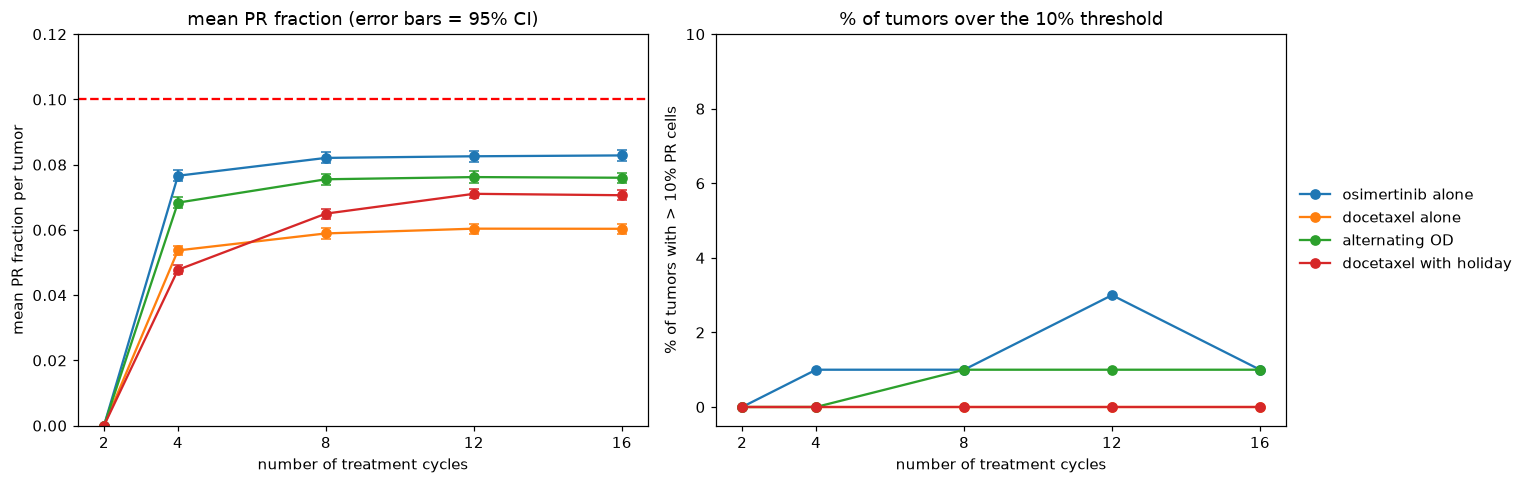

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

#left mean PR fraction with 95% CI error bars
for treatment in TREATMENTS:
    sub = pr_results[pr_results["treatment"] == treatment]
    axes[0].errorbar(sub["cycles"], sub["mean PR fraction"], yerr=1.96 * sub["SEM"],
                     fmt="o-", capsize=3, label=treatment)
axes[0].axhline(0.10, color="red", linestyle="--", label="10% threshold")
axes[0].set_xticks(CYCLE_LIST)
axes[0].set_ylim(0, 0.12)
axes[0].set_xlabel("number of treatment cycles")
axes[0].set_ylabel("mean PR fraction per tumor")
axes[0].set_title("mean PR fraction (error bars = 95% CI)")

#right % of tumors over 10%
for treatment in TREATMENTS:
    sub = pr_results[pr_results["treatment"] == treatment]
    axes[1].plot(sub["cycles"], sub["% tumors > 10% PR"], "o-", label=treatment)
axes[1].set_xticks(CYCLE_LIST)
axes[1].set_ylim(-0.5, 10)
axes[1].set_xlabel("number of treatment cycles")
axes[1].set_ylabel("% of tumors with > 10% PR cells")
axes[1].set_title("% of tumors over the 10% threshold")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)

plt.tight_layout()
plt.show()

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

A cell counts as PR if it is in P or NCP after 3+ consecutive drug cycles (starting state isn't counted, but holiday cycles are). Alternating starts with osimertinib, and the holiday schedule alternates docetaxel and holiday, starting with docetaxel. Only a few tumors cross 10% PR under any treatment. At [2, 4, 8, 12, 16] cycles, the percentage of tumors over 10% (respectively) is osimertinib [0%, 1%, 1%, 3%, 1%], alternating OD [0%, 0%, 1%,1%,1%], and 0% at every cycle count for both docetaxel alone and docetaxel + holiday (you can see that their lines overlap on the plot). The mean PR fraction stays below 10% for every treatement, and every 95% CI is fully below 0.10 (osimertinib at 8 cycles: 8.2% +/- 0.09% [SEM] with CI 0.0804-0.0837), which means the average tumor stays under the threshold. The few tumors that are over 10% are chance draws from the upper tail, meaning the 1-3% of tumors that do go over are just tumors that randomly ended up with a few more PR cells than average. Osimertinib makes the most PR cells (~8.2%), then alternating (~7.6%), then docetaxel + holiday (~6.5-7.1%), and finally docetaxel alone (~6%). As cycles increase, PR is 0 at 2 cycles (because PR takes at least 3 drug cycles), but then it jumps by 4 cycles and then levels off around 8 cycles. By then, most persistor cells have died or left the persistor states, so very few new cells can even become PR. Docetaxel + holiday keeps rising until around 12 cycles because holiday cycles don't kill that many cells, so more cells survive long enough to become persisters again during the next docetaxel cycle.

AI Use Note: Claude was used to help with coding syntax and brainstorming when creating some graphs and tables (mainly for Q8) in this lab.